# 01 · AI vs ML vs DL vs GenAI, in code

**Lecture:** *AI vs ML vs DL vs GenAI & the Biological Neuron Analogy* (05-08-2026), Part A · **Notes:** `../notes/02_ai_ml_dl_genai_and_the_neuron.md`

The lecture's hierarchy: **AI ⊃ ML ⊃ DL ⊃ GenAI**. The best way to feel the difference is to attack **one problem** at each level and compare:

| Level | What we'll build | Who decides the features? |
|---|---|---|
| **AI (rule-based, no learning)** | hand-written if-then rules | a human writes the rules |
| **ML (classical)** | logistic regression on **hand-engineered** features | a human designs the features; the model learns weights |
| **DL** | a neural network on **raw pixels** | the network learns its own features |
| **GenAI** | a small generative network that **creates new digits** | learns the data distribution itself |

The problem: scikit-learn's handwritten digits (1,797 images of 8×8 pixels, values 0–16). It ships with scikit-learn, so nothing to download. Everything runs in about a minute.

training images: 1257  test images: 540


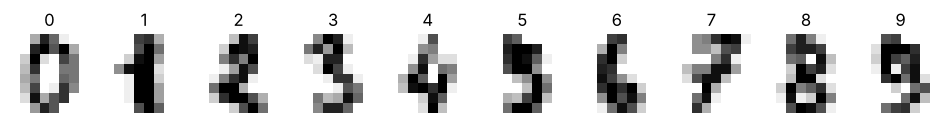

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
X, y, images = digits.data, digits.target, digits.images
X_tr, X_te, y_tr, y_te, img_tr, img_te = train_test_split(X, y, images, test_size=0.3, random_state=0, stratify=y)
print("training images:", len(X_tr), " test images:", len(X_te))
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for d, ax in enumerate(axes):
    ax.imshow(images[y == d][0], cmap="gray_r"); ax.set_title(str(d)); ax.axis("off")
plt.show()

## Level 1 · AI without learning: hand-written rules

The 1960s–80s "expert system" way: a human looks at the data and writes rules. To keep it fair, we only try to tell **0 from 1** (the easiest pair). A plausible human rule: "a **1** is a thin vertical stroke, so its ink sits in the middle columns; a **0** is a ring, so it has ink at the left and right edges and a hole in the middle."

In [2]:
def rule_based_0_or_1(img):
    middle_ink = img[:, 3:5].sum()                 # ink in the two centre columns
    side_ink = img[:, [1, 2, 5, 6]].sum()          # ink in the side columns
    centre_hole = img[3:5, 3:5].sum()              # a 0 has an empty centre
    return 1 if (middle_ink > side_ink * 0.5 and centre_hole > 10) else 0

mask = np.isin(y_te, [0, 1])
pred = np.array([rule_based_0_or_1(im) for im in img_te[mask]])
print(f"hand-written rules, 0 vs 1: {np.mean(pred == y_te[mask]):.1%} correct on {mask.sum()} test images")
print("and for all 10 digits? We'd need rules for every digit and every handwriting style. Nobody can write those by hand.")

hand-written rules, 0 vs 1: 97.2% correct on 109 test images
and for all 10 digits? We'd need rules for every digit and every handwriting style. Nobody can write those by hand.


That's **AI**: intelligent-looking behaviour from **rules a person wrote**, with no learning from data. It works for a narrow, clean task, but writing rules for all ten digits in every handwriting style is hopeless. That's the motivation for learning from data.

## Level 2 · Machine learning with hand-engineered features

Classical ML: a **human chooses the features** (measurements), and the algorithm **learns** how to weigh them. We design 8 features a person might think of, then let logistic regression learn the weights.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def engineered_features(img):
    ink = img > 4
    rows, cols = np.where(ink)
    return [img.sum(),                                     # total ink
            img[:4].sum() - img[4:].sum(),                 # top-heavy or bottom-heavy?
            img[:, :4].sum() - img[:, 4:].sum(),           # left-heavy or right-heavy?
            img[3:5, 3:5].sum(),                           # ink in the centre (hole?)
            (cols.max() - cols.min()) if len(cols) else 0, # width
            (rows.max() - rows.min()) if len(rows) else 0, # height
            np.abs(np.diff(img, axis=0)).sum(),            # vertical edges
            np.abs(np.diff(img, axis=1)).sum()]            # horizontal edges

F_tr = np.array([engineered_features(im) for im in img_tr]); F_te = np.array([engineered_features(im) for im in img_te])
ml = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(F_tr, y_tr)
print(f"ML on 8 hand-engineered features, all 10 digits: {ml.score(F_te, y_te):.1%}")

ML on 8 hand-engineered features, all 10 digits: 74.3%


It **learned** from data and handles all 10 digits, which is much better than rules. But it's limited by the **features a human thought of**. Ask yourself: what would be a good feature to tell 3 from 8, or 4 from 9? That's the human bottleneck the lecture calls **manual feature engineering**.

What if we give the same ML algorithm the **raw pixels** (64 numbers) instead?

In [4]:
ml_raw = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_tr, y_tr)
print(f"the same logistic regression on 64 raw pixels: {ml_raw.score(X_te, y_te):.1%}")

the same logistic regression on 64 raw pixels: 97.2%


On tiny, centred, clean 8×8 digits, raw pixels are already a good representation, so the linear model does well. On real photos (millions of pixels, objects anywhere, varying lighting), raw pixels fed to a linear model work badly, and that is exactly where deep learning's **learned features** make the difference.

## Level 3 · Deep learning: learn the features from raw pixels

A neural network with hidden layers takes the **raw pixels** and learns its own internal features in the hidden layers.

deep network (2 hidden layers) on raw pixels: 97.6%


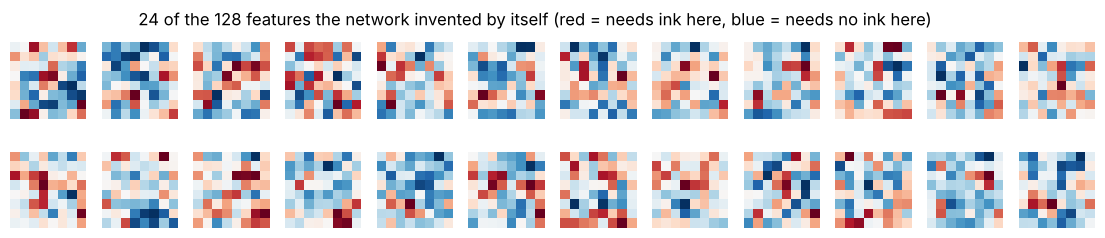

In [5]:
torch.manual_seed(0)
Xt_tr, Xt_te = torch.tensor(X_tr / 16, dtype=torch.float32), torch.tensor(X_te / 16, dtype=torch.float32)
yt_tr, yt_te = torch.tensor(y_tr), torch.tensor(y_te)
dl = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(dl.parameters(), lr=1e-3)
for epoch in range(60):
    perm = torch.randperm(len(Xt_tr))
    for i in range(0, len(perm), 64):
        idx = perm[i:i + 64]
        loss = nn.functional.cross_entropy(dl(Xt_tr[idx]), yt_tr[idx]); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    dl_acc = (dl(Xt_te).argmax(1) == yt_te).float().mean().item()
print(f"deep network (2 hidden layers) on raw pixels: {dl_acc:.1%}")

# What did the first hidden layer learn? Each neuron's 64 weights, drawn as an 8x8 picture
W1 = dl[0].weight.detach().numpy()
fig, axes = plt.subplots(2, 12, figsize=(14, 2.6))
for ax, w in zip(axes.ravel(), W1[:24]):
    ax.imshow(w.reshape(8, 8), cmap="RdBu"); ax.axis("off")
fig.suptitle("24 of the 128 features the network invented by itself (red = needs ink here, blue = needs no ink here)")
plt.show()

Nobody told the network to look for loops, strokes or centre holes. Its first layer **invented** its own detectors (the blobs and stroke patterns above). Deeper layers combine them. That's the lecture's **automatic, hierarchical feature learning**.

### "DL needs more data": measured
The lecture says deep learning needs more data than classical ML. Let's check how accuracy grows with training-set size, for the three learners.

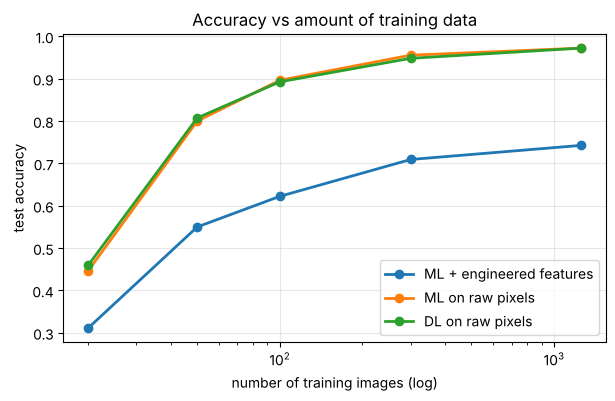

train size: [20, 50, 100, 300, 1257]
 ML + engineered features: 31%  55%  62%  71%  74%
         ML on raw pixels: 45%  80%  90%  96%  97%
         DL on raw pixels: 46%  81%  89%  95%  97%


In [6]:
def train_dl(Xa, ya, epochs=150, seed=0):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
    o = torch.optim.Adam(net.parameters(), lr=1e-3)
    Xa, ya = torch.tensor(Xa / 16, dtype=torch.float32), torch.tensor(ya)
    for _ in range(epochs):
        perm = torch.randperm(len(Xa))
        for i in range(0, len(perm), 64):
            idx = perm[i:i + 64]
            l = nn.functional.cross_entropy(net(Xa[idx]), ya[idx]); o.zero_grad(); l.backward(); o.step()
    with torch.no_grad():
        return (net(Xt_te).argmax(1) == yt_te).float().mean().item()

sizes = [20, 50, 100, 300, len(X_tr)]
res = {"ML + engineered features": [], "ML on raw pixels": [], "DL on raw pixels": []}
for n in sizes:
    idx = np.random.default_rng(0).choice(len(X_tr), n, replace=False) if n < len(X_tr) else np.arange(len(X_tr))
    res["ML + engineered features"].append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(F_tr[idx], y_tr[idx]).score(F_te, y_te))
    res["ML on raw pixels"].append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_tr[idx], y_tr[idx]).score(X_te, y_te))
    res["DL on raw pixels"].append(train_dl(X_tr[idx], y_tr[idx]))
plt.figure(figsize=(7, 4))
for k, v in res.items():
    plt.plot(sizes, v, "o-", lw=2, label=k)
plt.xscale("log"); plt.xlabel("number of training images (log)"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Accuracy vs amount of training data"); plt.show()
print("train size:", sizes)
for k, v in res.items():
    print(f"{k:>25}: " + "  ".join(f"{a:.0%}" for a in v))

**How to read it (honestly):**
- **The engineered-feature model is worst at every data size** (31% → 74%). My 8 hand-made features throw information away, and more data can't bring it back. That is the **human bottleneck** of manual feature engineering in action: the model can only be as good as the features someone thought of.
- **Logistic regression and the deep network on raw pixels track each other almost exactly** at every size (45% → 97% vs 46% → 97%). On tiny, clean, centred 8×8 digits, raw pixels are already an excellent representation, so the deep network's learned features have nothing extra to offer.
- So this dataset does **not** show "DL needs more data and then wins". That effect appears on **large, complex** data (real photos, speech, text), where a linear model on raw input is hopeless and only learned, layered features work, and where deep networks keep improving as data grows into the millions.
- It does confirm the lecture's misconception #4: **bigger is not always better**. On small, simple data, a classical model is just as accurate and far simpler.

## Level 4 · Generative AI: create digits that never existed

Everything so far was **discriminative**: image in, label out. A **generative** model learns what the data itself looks like, so it can **produce new samples**.

We train a tiny **variational autoencoder (VAE)**: it squeezes each digit into 2 numbers (a "code"), learns to rebuild the digit from the code, and learns codes that are spread like a simple bell curve. Afterwards we pick **brand-new random codes** and the decoder **draws new digits**. (You don't need the VAE maths yet. The point is the generate-new-content behaviour.)

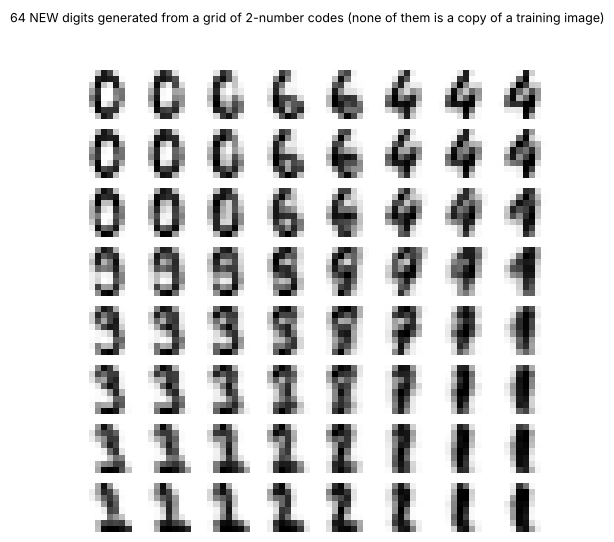

In [7]:
torch.manual_seed(0)
class TinyVAE(nn.Module):
    def __init__(self, z_dim=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 2 * z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, 128), nn.ReLU(), nn.Linear(128, 64), nn.Sigmoid())
    def forward(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)        # sample a code
        return self.dec(z), mu, logvar

vae = TinyVAE(); opt = torch.optim.Adam(vae.parameters(), lr=2e-3)
Xall = torch.tensor(X / 16, dtype=torch.float32)
for epoch in range(300):
    perm = torch.randperm(len(Xall))
    for i in range(0, len(perm), 128):
        xb = Xall[perm[i:i + 128]]
        recon, mu, logvar = vae(xb)
        rec_loss = nn.functional.binary_cross_entropy(recon, xb, reduction="sum")
        kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp())          # keep codes bell-shaped
        loss = (rec_loss + kl) / len(xb); opt.zero_grad(); loss.backward(); opt.step()

# GENERATE: random codes in, new digits out
with torch.no_grad():
    grid = torch.tensor([[a, b] for b in np.linspace(2, -2, 8) for a in np.linspace(-2, 2, 8)], dtype=torch.float32)
    new_digits = vae.dec(grid).numpy().reshape(-1, 8, 8)
fig, axes = plt.subplots(8, 8, figsize=(6, 6))
for ax, im in zip(axes.ravel(), new_digits):
    ax.imshow(im, cmap="gray_r"); ax.axis("off")
fig.suptitle("64 NEW digits generated from a grid of 2-number codes (none of them is a copy of a training image)", fontsize=9)
plt.show()

In [8]:
# Prove they are new: distance from each generated digit to its NEAREST training image
gen = new_digits.reshape(64, -1); train_pix = X / 16
nearest = np.sqrt(((gen[:, None, :] - train_pix[None, :, :]) ** 2).sum(-1)).min(axis=1)
typical = np.sqrt(((train_pix[:200, None, :] - train_pix[None, :, :]) ** 2).sum(-1))
np.fill_diagonal(typical[:, :200], np.inf)
print(f"generated digit -> nearest training digit: median distance {np.median(nearest):.2f}")
print(f"real digit -> its nearest OTHER real digit: median distance {np.median(typical.min(axis=1)):.2f}")

generated digit -> nearest training digit: median distance 0.99
real digit -> its nearest OTHER real digit: median distance 1.05


- The generated digits are **plausible but new**: they're about as far from their nearest training image as real digits are from each other, so the model isn't simply copying.
- Moving smoothly across the grid morphs one digit into another, because the model has learned a continuous "space of digits".
- They're blurry. A 2-number code and an 8×8 world is a toy. ChatGPT, Claude, Midjourney and other real GenAI systems apply the same "learn the data distribution, then sample from it" idea with **billions** of parameters and **web-scale** data, mostly with **Transformer** and diffusion architectures, as the lecture says.

## The four levels side by side (this notebook's evidence)

In [9]:
print(f"{'level':<10}{'approach':<42}{'features chosen by':<22}{'result'}")
print(f"{'AI':<10}{'hand-written rules':<42}{'a human (rules)':<22}{np.mean(pred == y_te[mask]):.0%} on 0-vs-1 only")
print(f"{'ML':<10}{'logistic regression, engineered features':<42}{'a human (features)':<22}{ml.score(F_te, y_te):.0%} on all 10 digits")
print(f"{'DL':<10}{'2-hidden-layer network, raw pixels':<42}{'the network itself':<22}{dl_acc:.0%} on all 10 digits")
print(f"{'GenAI':<10}{'tiny VAE':<42}{'the network itself':<22}creates new digits")

level     approach                                  features chosen by    result
AI        hand-written rules                        a human (rules)       97% on 0-vs-1 only
ML        logistic regression, engineered features  a human (features)    74% on all 10 digits
DL        2-hidden-layer network, raw pixels        the network itself    98% on all 10 digits
GenAI     tiny VAE                                  the network itself    creates new digits


## ✅ Check yourself
1. Put these in the hierarchy: a chess program with hand-coded rules, a Naive Bayes spam filter, a CNN tagging beach photos, ChatGPT writing a poem. *(AI only; AI+ML; AI+ML+DL; AI+ML+DL+GenAI)*
2. What is feature engineering, and at which level does it stop being manual? *(choosing which measurements the model sees; DL learns them automatically)*
3. Why did the hand-engineered-feature model stay worst even with all the training data? *(its 8 features discard information that more data can't recover; the model is limited by the features a human chose)*
4. What makes a model *generative* rather than *discriminative*? *(it models the data itself and can produce new samples, rather than only mapping inputs to labels)*
5. "GenAI is a completely different technology from DL." True or false? *(False: it's deep learning applied at scale to content generation)*